In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm

import matplotlib as mpl

from scipy import interpolate
import scipy.optimize

from copy import deepcopy
import time
from tqdm import tqdm

from ngsolve import *
from ngsolve.webgui import Draw
from netgen.csg import *

from netgen.occ import *
from netgen.meshing import IdentificationType

# my functions
from helper_functions import *
from dipole_poisson_solver_tmdc import dipole_poisson_solver

In [2]:
### unit-system: Angstrom = 1, eV = 1, e_charge = 1

### choices, see lammps metal system: https://docs.lammps.org/units.html

Angstrom = 1
eV = 1
e_charge = 1
Volt = 1

### independent

finestructure_constant = 0.0072973525643 # Finestructure constant, independent of unit-system   , https://en.wikipedia.org/wiki/Fine-structure_constant

### derived

hbar = 6.582119569 * pow(10.0, -4.0) ## eV * pico seconds, 1 pico second = 10^(-12) seconds

### units of time are in pico seconds, this implies units of velocity are in Angstrom / picoseconds

c_speed_of_light = 2.99792458 * pow(10.0, 6.0) ## Angstrom/pico seconds

pico_second = 1

nm = 10 ## 1nm = 10 Angstrom


hbar_times_c = 1973  # eV * Angstrom  # https://en.wikipedia.org/wiki/Planck_constant#Reduced_Planck_constant
h_times_c = 2.0 * np.pi * hbar_times_c

epsilon_0 = (e_charge * e_charge) / (2.0 * finestructure_constant * h_times_c)    # https://en.wikipedia.org/wiki/Vacuum_permittivity
mu_0 = 1.0 / (c_speed_of_light * epsilon_0)    # https://en.wikipedia.org/wiki/Vacuum_permeability
mu_0 /= c_speed_of_light ### don't divide by c^2 immediately

######################
######################
######################


### constants
a_lattice = 2.46

grapheneheight = 3.35 # Angstrom

blg_grapheneheight = grapheneheight ### see Jung & MacDonald PRB 89, 035405 (2014) #2.0 * grapheneheight
MoS2_1L_height = 12.29 # this is the perpendicular unit cell size according to the Ab initio tight binding paper

bilayer_graphene_area, bilayer_graphene_volume = blg_area_vol(a_lattice, blg_grapheneheight, Angstrom)
print(blg_grapheneheight)

3.35


In [3]:
# eps tensor
inplane_hBn_bulk = 4.98 ### see https://www.nature.com/articles/s41699-018-0050-x 
outofplane_hBn_bulk = 3.03

inplane_graphene = 1.8 ### https://pubs.acs.org/doi/10.1021/nl303611v
outofplane_graphene = 3

inplane_MoS2 = 15.4 ### https://www.nature.com/articles/s41699-018-0050-x
outofplane_MoS2 = 6.1

In [60]:
# tmdc idos
idos_tmdc = np.load('DOS_calculations/idos_MoS2_energy_deviation_15e-3.npy')
energies_tmdc = np.load('DOS_calculations/idos_MoS2_energies_energy_deviation_15e-3.npy')
energies_tmdc = energies_tmdc - 0.5
print(idos_tmdc.shape)

(1334,)


2.2488755622188905


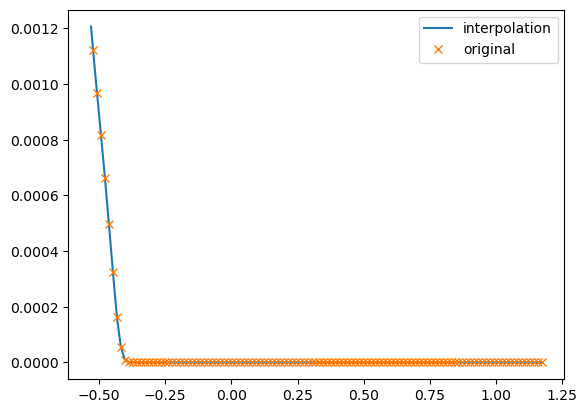

In [61]:
idos_tmdc_interpolated = scipy.interpolate.interp1d(energies_tmdc, idos_tmdc, kind='linear') # use other interpolator here
en_min = energies_tmdc[0]
en_max = energies_tmdc[-1]

n_energies_new = 3000
new_energies = np.linspace(en_min, en_max, n_energies_new)
energy_factor = n_energies_new/idos_tmdc.shape[0]
print(energy_factor)

plot_min = 665#680 #665
plot_max = 779
new_plot_min = int(energy_factor * plot_min)
new_plot_max = int(energy_factor * plot_max)
plt.plot(new_energies[new_plot_min:new_plot_max], idos_tmdc_interpolated(new_energies)[new_plot_min:new_plot_max], '-',label='interpolation')
plt.plot(energies_tmdc[plot_min:plot_max], idos_tmdc[plot_min:plot_max], 'x',label='original')
plt.legend()

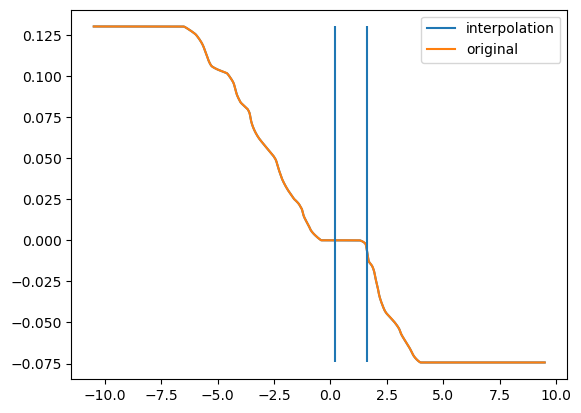

In [62]:
plt.plot(new_energies, idos_tmdc_interpolated(new_energies), label='interpolation')
plt.plot(energies_tmdc, idos_tmdc, label='original')
plt.vlines(0.2, np.min(idos_tmdc), np.max(idos_tmdc))
plt.vlines(1.6, np.min(idos_tmdc), np.max(idos_tmdc))
#plt.xlim((-0.1, 0))
plt.legend()

In [63]:
print(idos_tmdc_interpolated(1))

1.6504161240747046e-17


In [64]:
idx = np.argmin(abs(energies_tmdc))
print(idos_tmdc[idx +2])

-1.6504161240747046e-17


In [65]:
vac_box_width = 250 #700 * nm
height_bottom = 15 * nm 
height_top = height_bottom
vac_box_width = height_bottom * 15 # box width is 10 times hbn thickness
dipole_moment_debye = 40

sphere_radius = 3 # 3
benzen_a = 1.4 # Angstrom
benzen_diameter = 2 * benzen_a
dipole_position = 6 # 0.02 * vac_box_width # basically 0


dipole_d = 3 * benzen_diameter 

back_gate = 0.05 - 0.5
max_h = vac_box_width/10 #vac_box_width/15
hbn_maxh = 0.8
blg_maxh = 0.3

cut_percentage = 0.2
larger_cut_percentage = 0.7
lam = 100000

fem_n = 300
epsilon_z = 1e-4
print('simulation dimensions in Angstrom: ')
print('hBb thickness: ', height_bottom)
print('blg thichness: ', blg_grapheneheight)
print('box width: ', vac_box_width)
print('dipole d: ', dipole_d)
print('dipole height over hBn: ', dipole_position)
print('dipole sphere radius: ', sphere_radius)

simulation dimensions in Angstrom: 
hBb thickness:  150
blg thichness:  3.35
box width:  2250
dipole d:  8.399999999999999
dipole height over hBn:  6
dipole sphere radius:  3


In [66]:
test_solver = dipole_poisson_solver(dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_MoS2, outofplane_MoS2, epsilon_0)
test_solver.build_geometry(vac_box_width, height_bottom, height_top, MoS2_1L_height, sphere_radius, max_h, hbn_maxh, blg_maxh)

In [67]:
test_solver.solve_without_tmdc(back_gate)

In [68]:
edge_length = vac_box_width
hBn_thickness = height_bottom
tmdc_thickness = MoS2_1L_height

increment = edge_length / (fem_n - 1)

xs   = np.linspace(0, edge_length, fem_n)
ys   = np.linspace(0, edge_length, fem_n)

zs_Bot = np.array(hBn_thickness + epsilon_z)

zs_Mid = np.array(hBn_thickness + tmdc_thickness/2)

zs_Top = np.array(hBn_thickness + tmdc_thickness - epsilon_z)

dummy_m_x, dummy_m_y, dummy_m_z_b = np.meshgrid(xs, ys, zs_Bot)

dummy_m_z_m = np.ones((fem_n,fem_n,1), dtype=np.float64) * zs_Mid
dummy_m_z_t = np.ones((fem_n,fem_n,1), dtype=np.float64) * zs_Top

ptsBot = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_b)]).T
    
ptsMid = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_m)]).T

ptsTop = np.array([np.ravel(dummy_m_x), np.ravel(dummy_m_y), np.ravel(dummy_m_z_t)]).T
            
meshptsTop = test_solver.mesh_dipole(ptsTop[:,0], ptsTop[:,1], ptsTop[:,2])
meshptsMid = test_solver.mesh_dipole(ptsMid[:,0], ptsMid[:,1], ptsMid[:,2])
meshptsBot = test_solver.mesh_dipole(ptsBot[:,0], ptsBot[:,1], ptsBot[:,2])

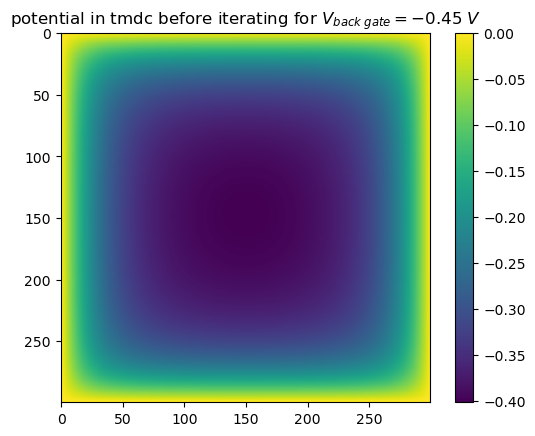

In [69]:
plt.imshow(test_solver.gfu_solveonce(meshptsMid).reshape((fem_n, fem_n)))
plt.title(f'potential in tmdc before iterating for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

In [70]:
print(idos_tmdc_interpolated(0.25))

-1.6504161240747046e-17


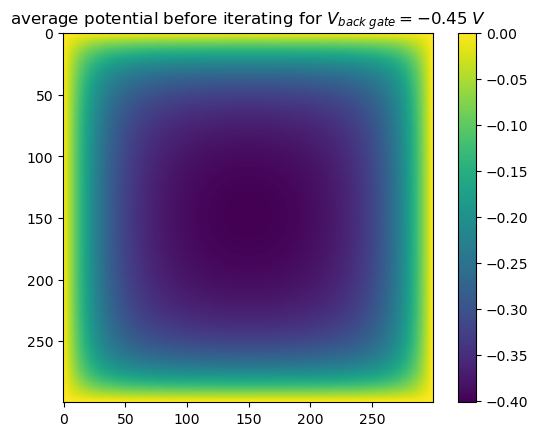

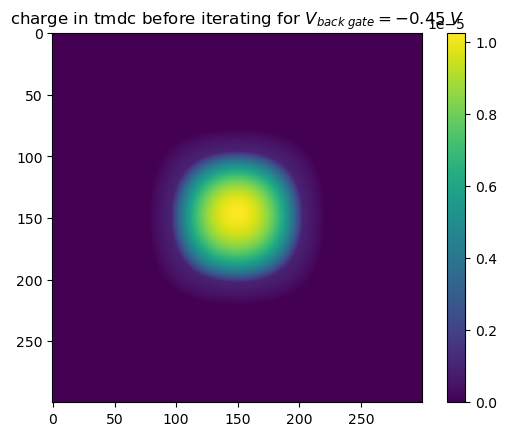

In [71]:
potTop    = test_solver.gfu_solveonce(meshptsTop).reshape((fem_n, fem_n))
potBottom = test_solver.gfu_solveonce(meshptsBot).reshape((fem_n, fem_n))
        
average_pot  =  0.5*(potTop+potBottom)

plt.imshow(average_pot)
plt.title(f'average potential before iterating for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

plt.imshow(idos_tmdc_interpolated(average_pot))
plt.title(f'charge in tmdc before iterating for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

52201


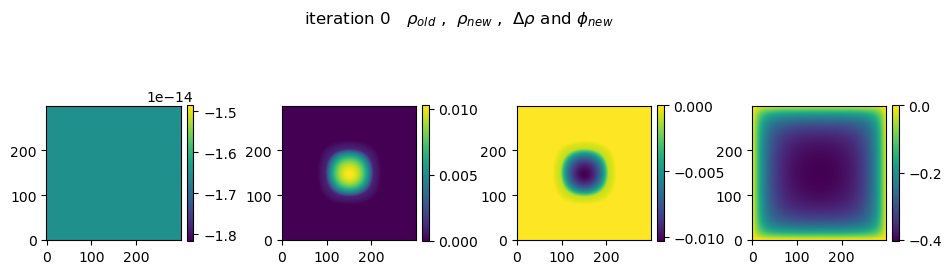

iteration:  0
# 0   rho_n-1 - rho_n (max):  1.0271031972594796e-05
# 0   |q_n-1 - q_n| :  41.0760282025325


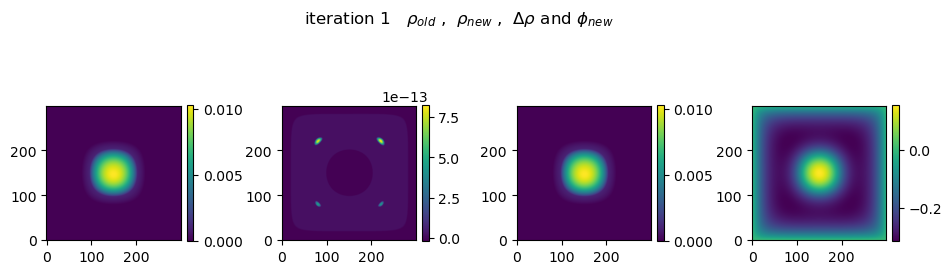

iteration:  1
# 1   rho_n-1 - rho_n (max):  1.0271031972594796e-05
# 1   |q_n-1 - q_n| :  41.07602820105071


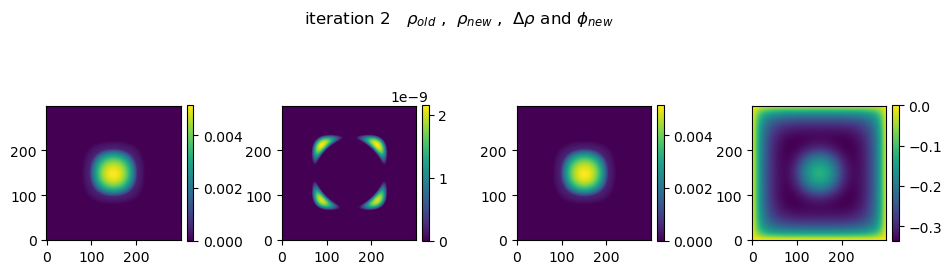

iteration:  2
# 2   rho_n-1 - rho_n (max):  5.13551598629616e-06
# 2   |q_n-1 - q_n| :  20.538008471081326


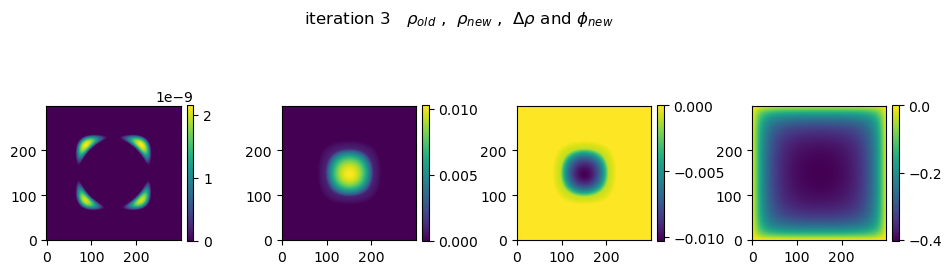

iteration:  3
# 3   rho_n-1 - rho_n (max):  1.027102804409354e-05
# 3   |q_n-1 - q_n| :  41.0759815686547


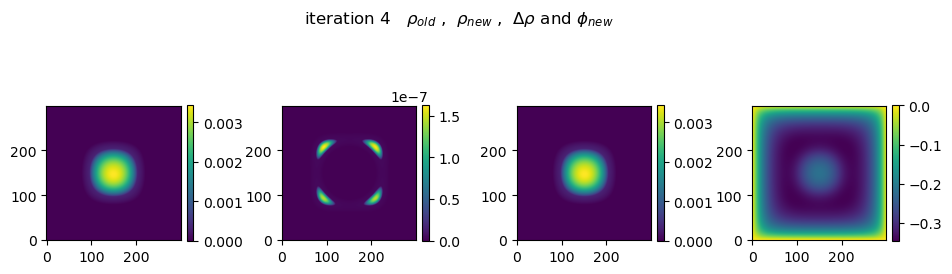

iteration:  4
# 4   rho_n-1 - rho_n (max):  3.4236776250741865e-06
# 4   |q_n-1 - q_n| :  13.69176707229058


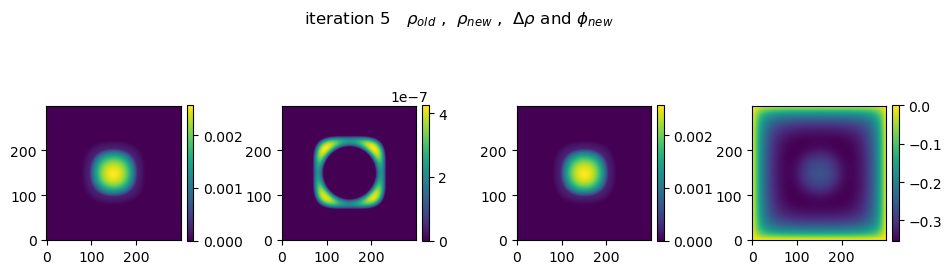

iteration:  5
# 5   rho_n-1 - rho_n (max):  2.567757877923497e-06
# 5   |q_n-1 - q_n| :  10.266913380800966


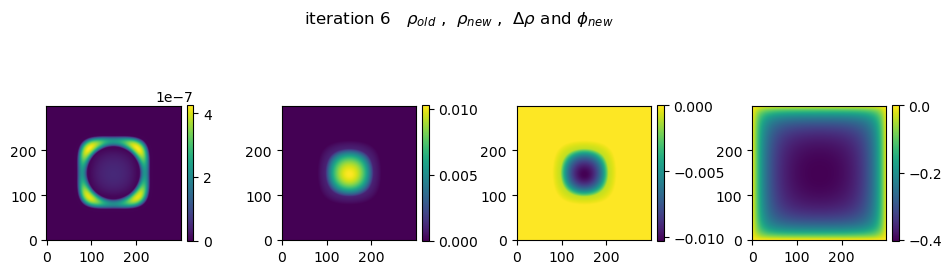

iteration:  6
# 6   rho_n-1 - rho_n (max):  1.0267087975827293e-05
# 6   |q_n-1 - q_n| :  41.04178033245206


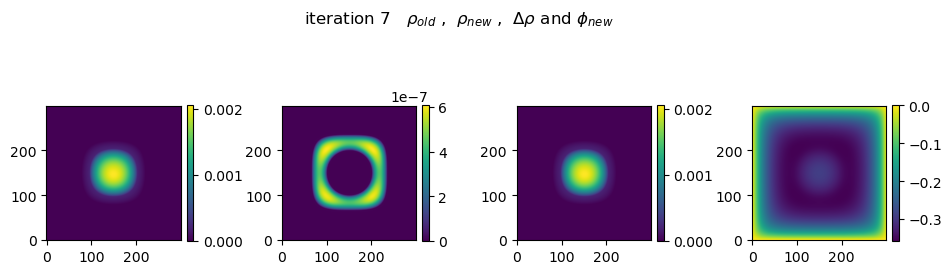

iteration:  7
# 7   rho_n-1 - rho_n (max):  2.054396806991081e-06
# 7   |q_n-1 - q_n| :  8.209943423872195


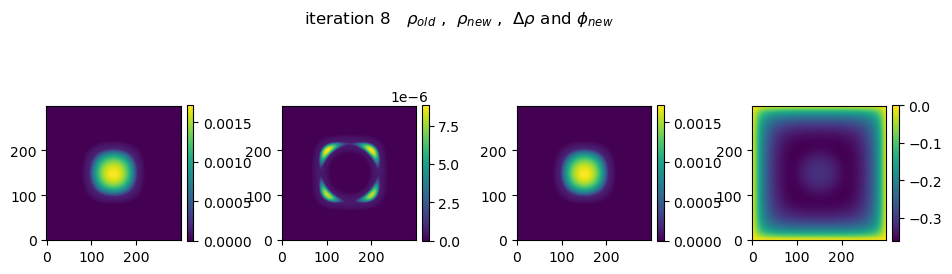

iteration:  8
# 8   rho_n-1 - rho_n (max):  1.7118682557222864e-06
# 8   |q_n-1 - q_n| :  6.825323951510941


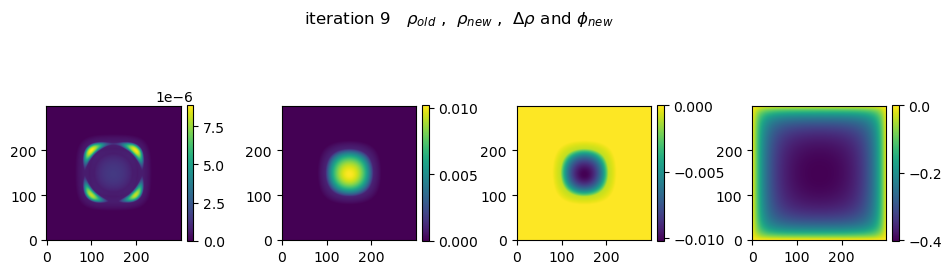

iteration:  9
# 9   rho_n-1 - rho_n (max):  1.01929316499996e-05
# 9   |q_n-1 - q_n| :  40.53673921715154


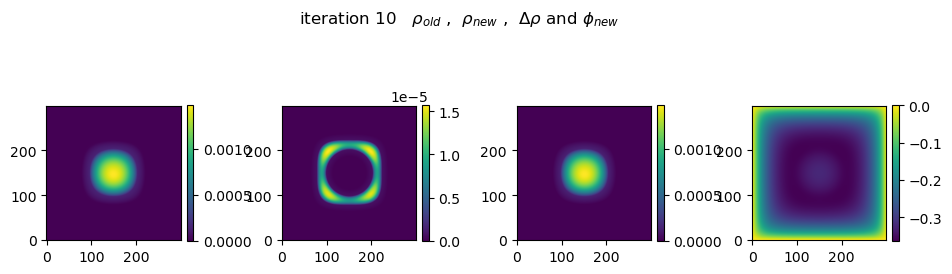

iteration:  10
# 10   rho_n-1 - rho_n (max):  1.4689552558284779e-06
# 10   |q_n-1 - q_n| :  5.795260553851027


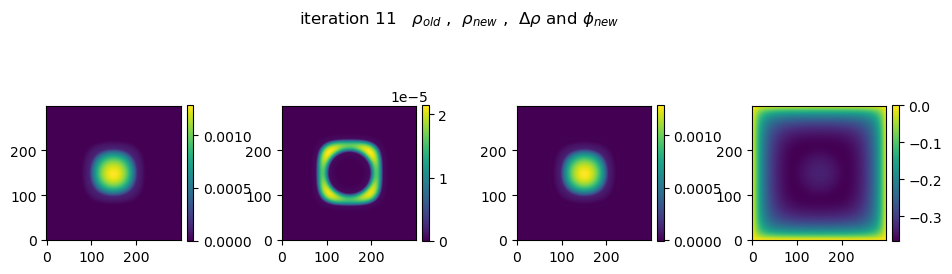

iteration:  11
# 11   rho_n-1 - rho_n (max):  1.2840904232732084e-06
# 11   |q_n-1 - q_n| :  5.0129670904210535


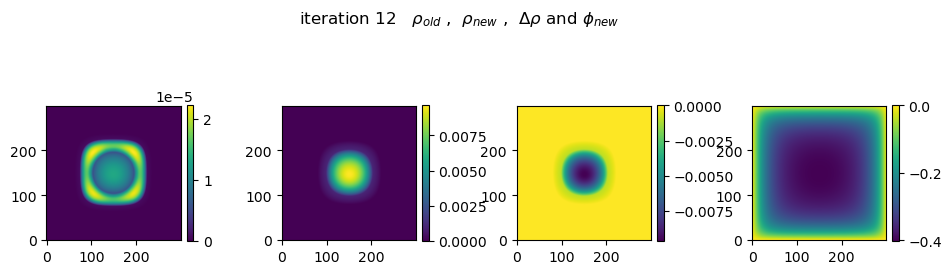

iteration:  12
# 12   rho_n-1 - rho_n (max):  9.616897834304786e-06
# 12   |q_n-1 - q_n| :  36.90416252061936


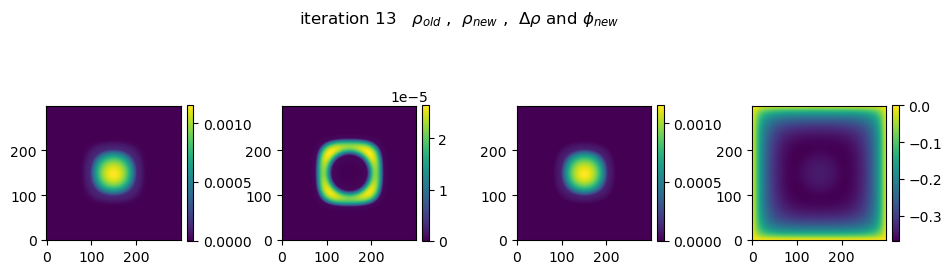

iteration:  13
# 13   rho_n-1 - rho_n (max):  1.1519115137122764e-06
# 13   |q_n-1 - q_n| :  4.363372271976601


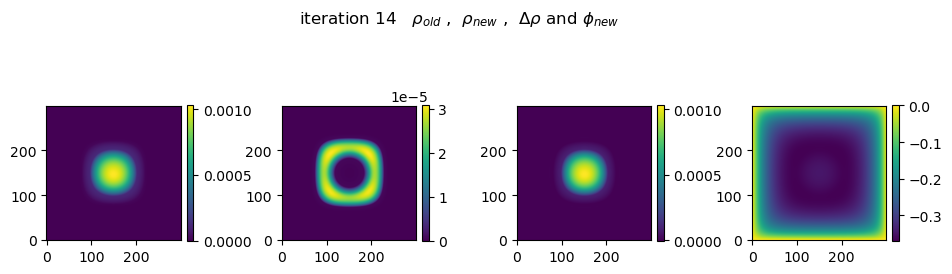

iteration:  14
# 14   rho_n-1 - rho_n (max):  1.0298863511856555e-06
# 14   |q_n-1 - q_n| :  3.846257110942871


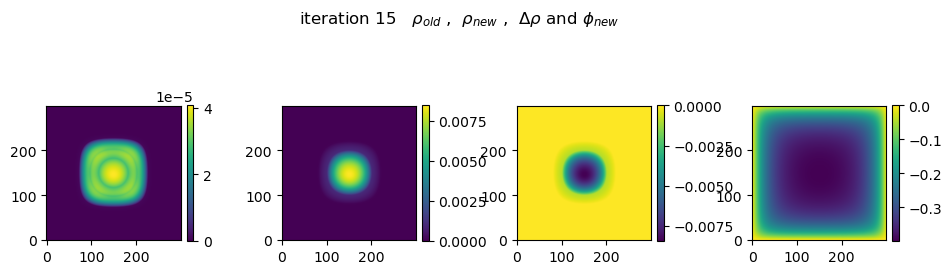

iteration:  15
# 15   rho_n-1 - rho_n (max):  8.415334852671234e-06
# 15   |q_n-1 - q_n| :  30.53742699540511


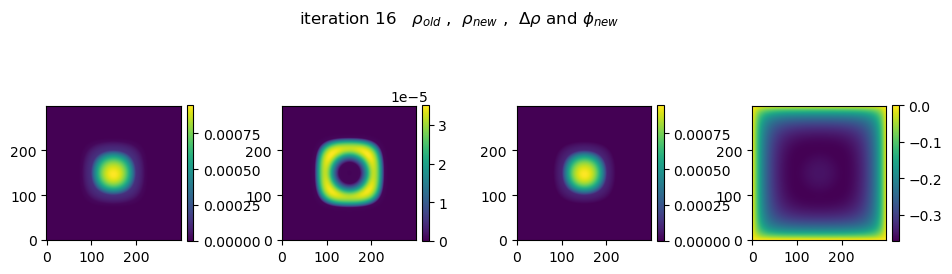

iteration:  16
# 16   rho_n-1 - rho_n (max):  9.446370208908899e-07
# 16   |q_n-1 - q_n| :  3.3691831699525876


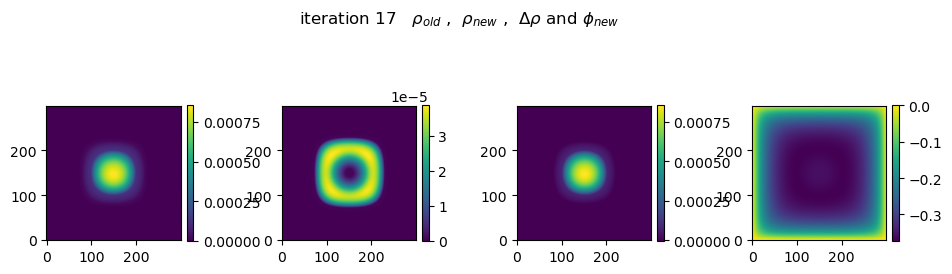

iteration:  17
# 17   rho_n-1 - rho_n (max):  8.53116468213617e-07
# 17   |q_n-1 - q_n| :  2.984368805615254


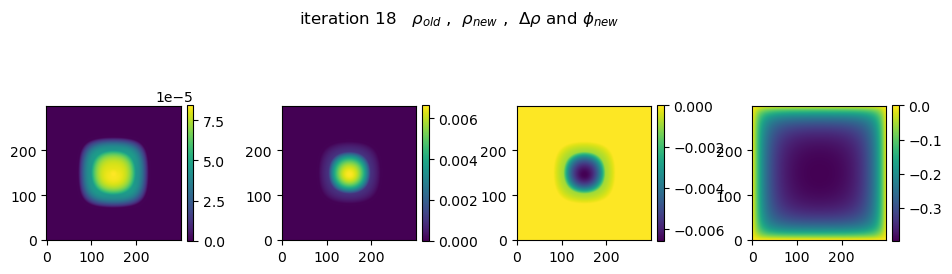

iteration:  18
# 18   rho_n-1 - rho_n (max):  6.552051883104965e-06
# 18   |q_n-1 - q_n| :  22.21278356420253


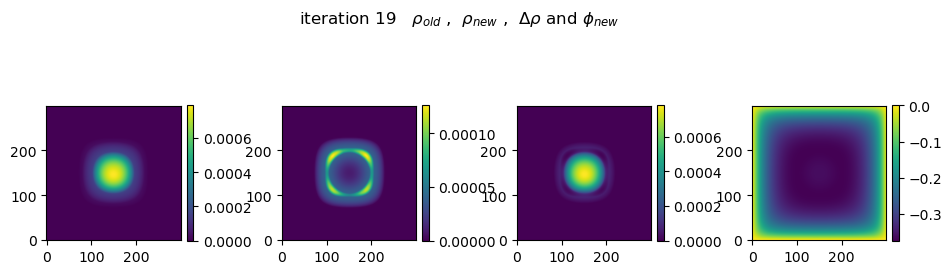

iteration:  19
# 19   rho_n-1 - rho_n (max):  7.789953703031021e-07
# 19   |q_n-1 - q_n| :  2.501837623802554


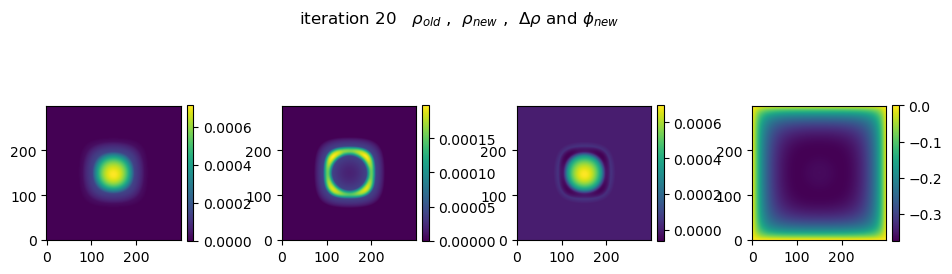

iteration:  20
# 20   rho_n-1 - rho_n (max):  6.946178778015038e-07
# 20   |q_n-1 - q_n| :  1.8901550778214622


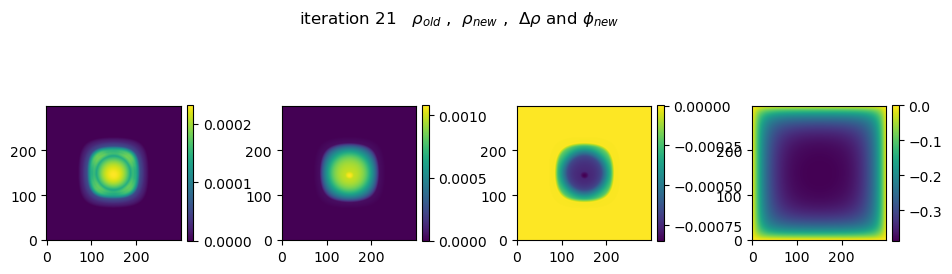

iteration:  21
# 21   rho_n-1 - rho_n (max):  8.466170630339509e-07
# 21   |q_n-1 - q_n| :  4.687719429106972


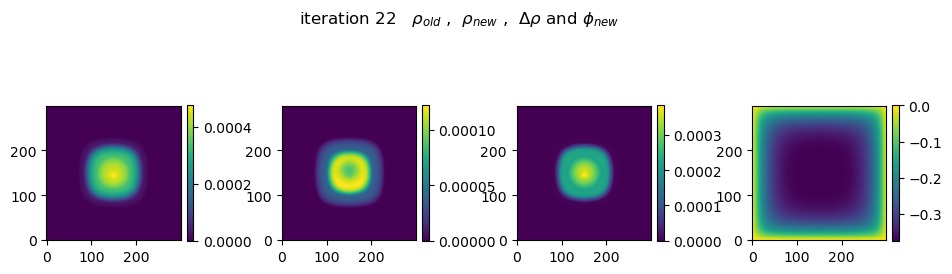

iteration:  22
# 22   rho_n-1 - rho_n (max):  3.835404830485103e-07
# 22   |q_n-1 - q_n| :  2.0224370114425994


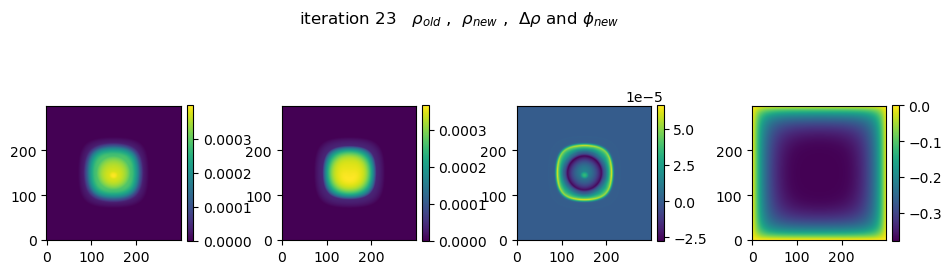

iteration:  23
# 23   rho_n-1 - rho_n (max):  6.59442891787611e-08
# 23   |q_n-1 - q_n| :  0.14163881390573962


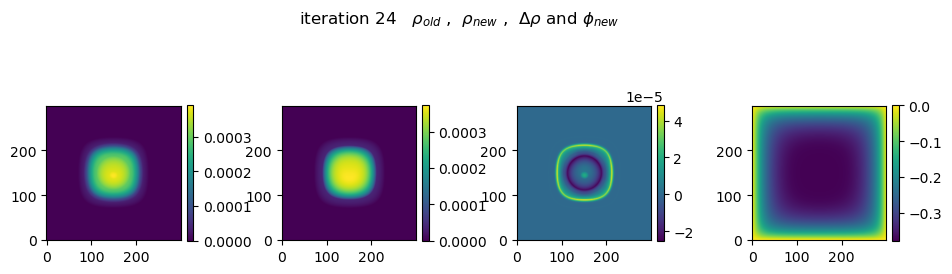

iteration:  24
# 24   rho_n-1 - rho_n (max):  4.818336868702563e-08
# 24   |q_n-1 - q_n| :  0.04008844404970624


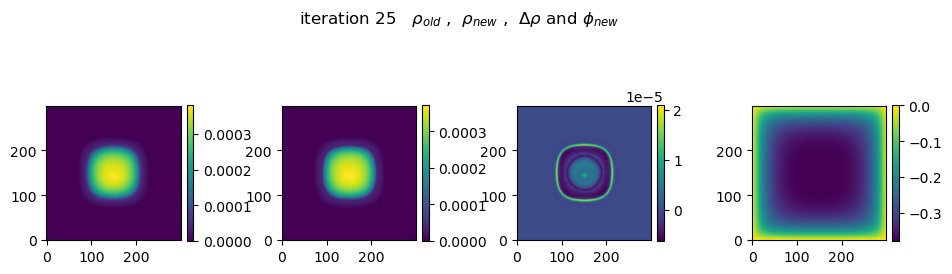

iteration:  25
# 25   rho_n-1 - rho_n (max):  2.0915286301911756e-08
# 25   |q_n-1 - q_n| :  0.004044851490034418


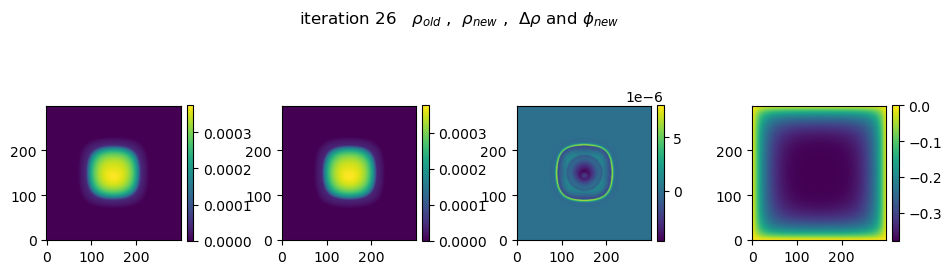

iteration:  26
# 26   rho_n-1 - rho_n (max):  7.963015548563032e-09
# 26   |q_n-1 - q_n| :  0.0010195352307262873


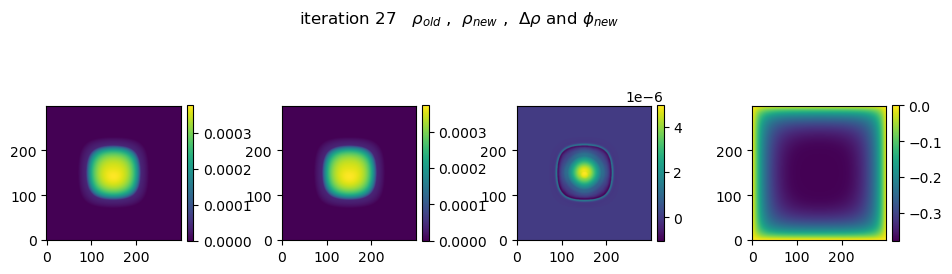

iteration:  27
# 27   rho_n-1 - rho_n (max):  4.933450450136972e-09
# 27   |q_n-1 - q_n| :  0.010162496009854305


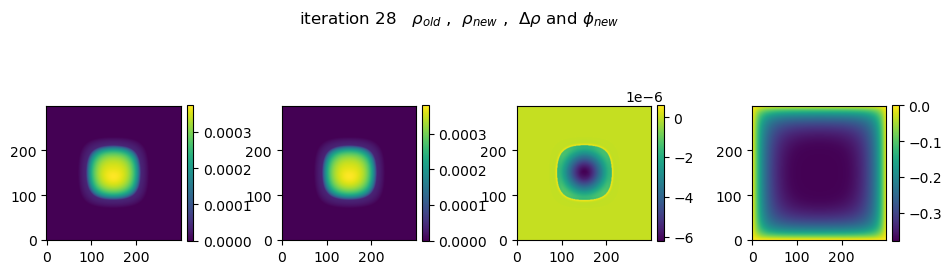

iteration:  28
# 28   rho_n-1 - rho_n (max):  6.192641331472132e-09
# 28   |q_n-1 - q_n| :  0.02537136630006387


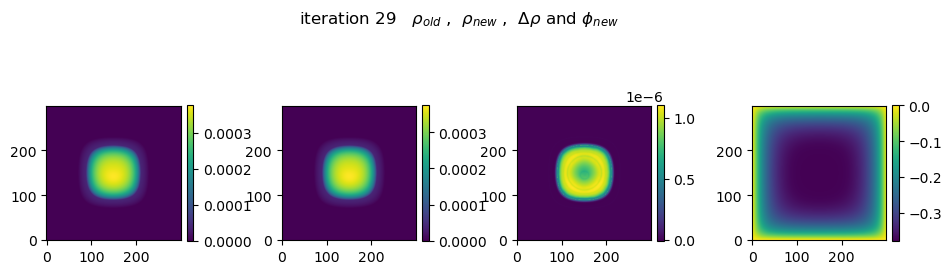

iteration:  29
# 29   rho_n-1 - rho_n (max):  1.0986471716571481e-09
# 29   |q_n-1 - q_n| :  0.008388995590755233


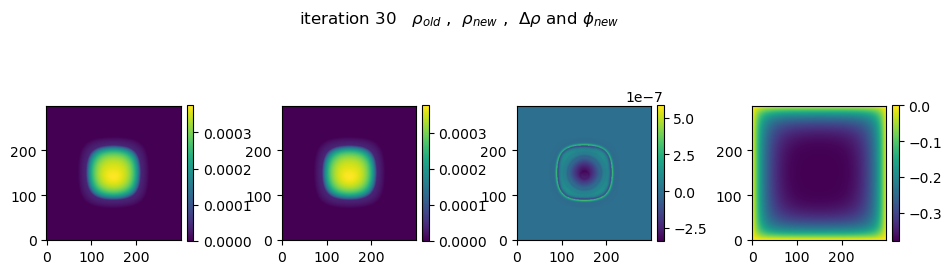

iteration:  30
# 30   rho_n-1 - rho_n (max):  5.836782892092193e-10
# 30   |q_n-1 - q_n| :  1.9926930960867395e-05


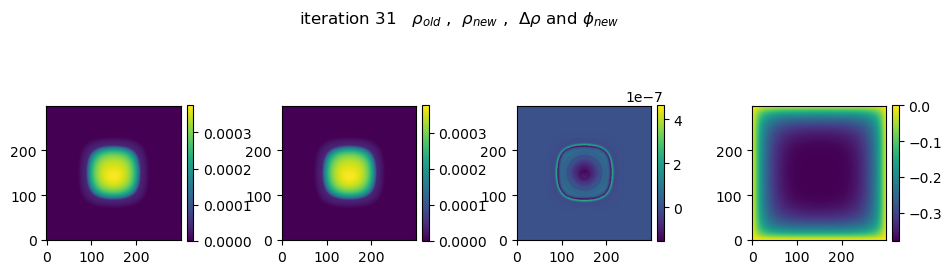

iteration:  31
# 31   rho_n-1 - rho_n (max):  4.6252684434050416e-10
# 31   |q_n-1 - q_n| :  0.00012271351908221817


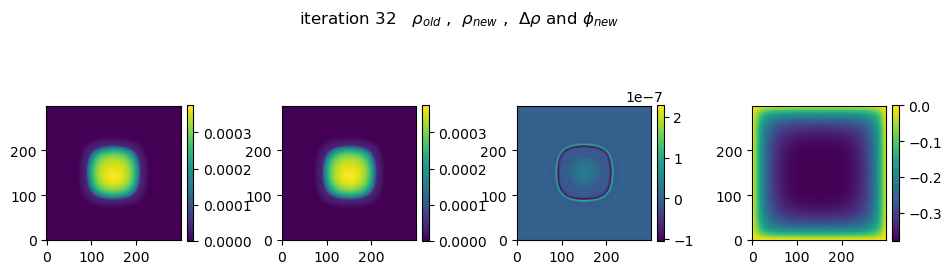

iteration:  32
# 32   rho_n-1 - rho_n (max):  2.2728512498099599e-10
# 32   |q_n-1 - q_n| :  3.2587433654196474e-05


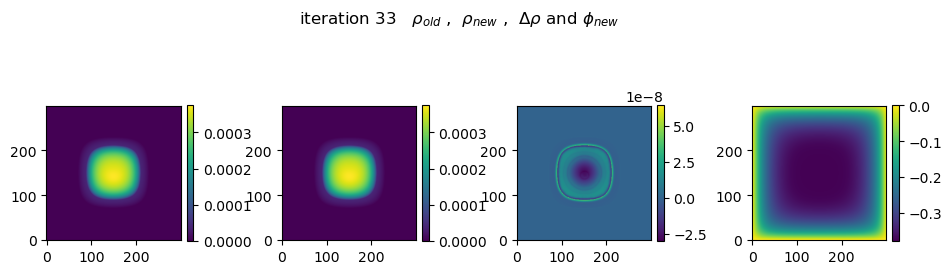

iteration:  33
# 33   rho_n-1 - rho_n (max):  6.417289124266893e-11
# 33   |q_n-1 - q_n| :  4.702330916783737e-05


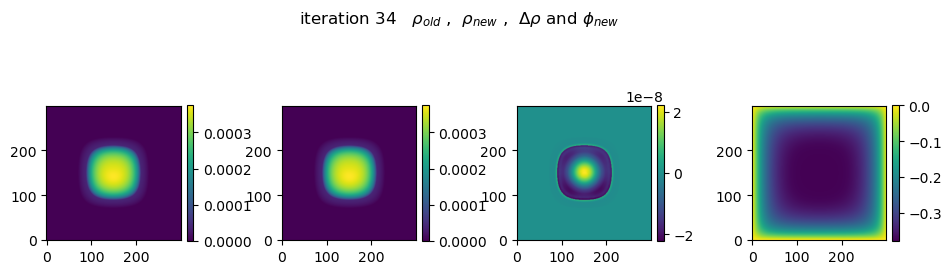

iteration:  34
# 34   rho_n-1 - rho_n (max):  2.2087881609384458e-11
# 34   |q_n-1 - q_n| :  8.631129436720286e-05


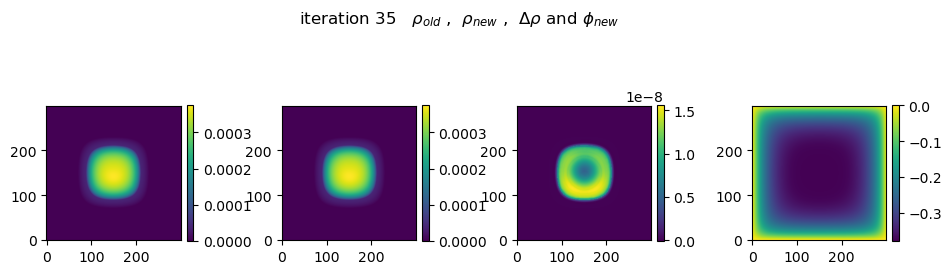

iteration:  35
# 35   rho_n-1 - rho_n (max):  1.555234349042311e-11
# 35   |q_n-1 - q_n| :  0.00010416559095860478


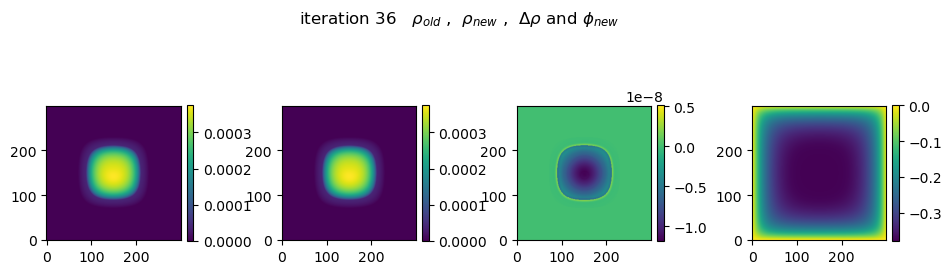

iteration:  36
# 36   rho_n-1 - rho_n (max):  1.1829076104244825e-11
# 36   |q_n-1 - q_n| :  6.002570601637558e-05
solver takes  18.18109965324402  seconds and  37  iterations
charge = 2.369213714792265


In [72]:
print(test_solver.ndofs_potential_fes)
test_solver.solve(fem_n, epsilon_z, idos_tmdc_interpolated, en_min, en_max, cut_percentage, larger_cut_percentage, lam, use_abs=True, starting_alpha=0.01) # trying different starting alphas

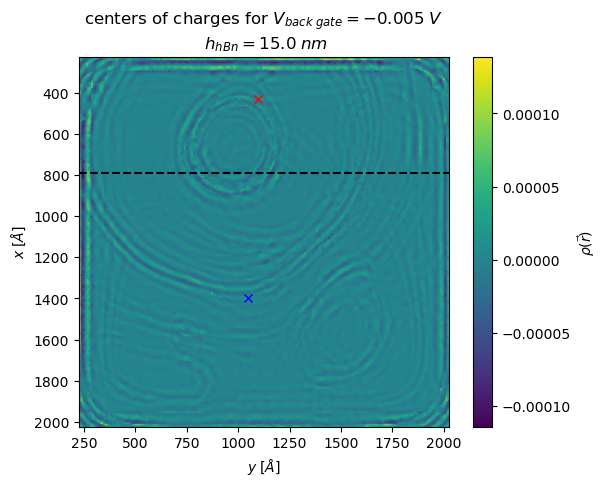

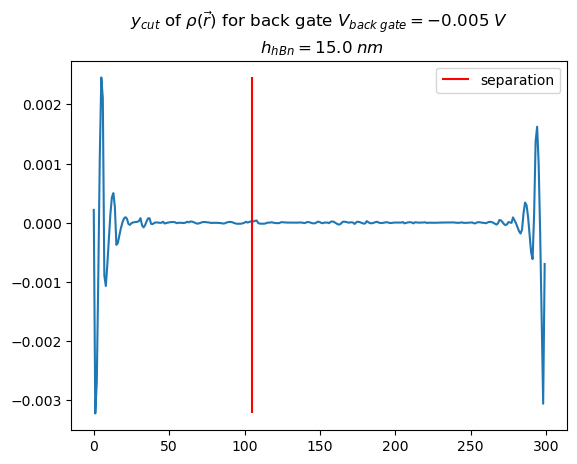

In [ ]:
cut_index = int(test_solver.cut_percentage/2 * test_solver.fem_n)
larger_cut_index = int(test_solver.larger_cut_percentage/2 * test_solver.fem_n)

dx = test_solver.vac_box_width/(test_solver.fem_n - 1)
x_max = (test_solver.fem_n - 1) * dx
x = np.linspace(0, x_max, test_solver.fem_n)
y = np.linspace(0, x_max, test_solver.fem_n)

x = x[cut_index:test_solver.fem_n - cut_index]
y = y[cut_index:test_solver.fem_n - cut_index]
x_sep = x[test_solver.sep_index] 


plt.imshow(test_solver.induced_charge, extent=[x.min(), x.max(), y.max(), y.min()])
plt.plot(test_solver.center_of_charge_top[1], test_solver.center_of_charge_top[0], 'rx')
plt.plot(test_solver.center_of_charge_bot[1], test_solver.center_of_charge_bot[0], 'bx')
#plt.plot(center_of_charge_top[1], center_of_charge_top[0], 'rx')
#plt.plot(center_of_charge_bot[1], center_of_charge_bot[0], 'bx')
plt.hlines(x_sep, x.min(), x.max(), color='black', linestyle='dashed')
plt.colorbar(label='$\\rho(\\vec{{r}})$')
plt.title(f'centers of charges for $V_{{back\\;gate}}={back_gate}\\;V$\n $h_{{hBn}}={test_solver.height_bottom/10}\\;nm$')
plt.xlabel('$y\\;[\\AA]$')
plt.ylabel('$x\\;[\\AA]$')

plt.show()

y_test = test_solver.cut_through_charge#[larger_cut_index:test_solver.fem_n - larger_cut_index]
plt.plot(y_test)
plt.vlines(test_solver.sep_index + cut_index, np.min(test_solver.cut_through_charge), np.max(test_solver.cut_through_charge), color='r', label='separation')
plt.title(f'$y_{{cut}}$ of $\\rho(\\vec{{r}})$ for back gate $V_{{back\\;gate}}={back_gate} \\; V$\n $h_{{hBn}}={test_solver.height_bottom/10}\\;nm$')
plt.legend()

plt.show()

In [ ]:
print(test_solver.sol.success)

False


In [ ]:
#Draw(test_solver.mesh_dipole)

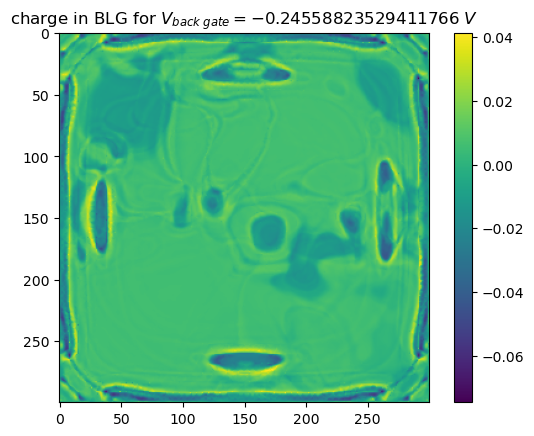

In [ ]:
plt.imshow(test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n)))
plt.title(f'charge in BLG for $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

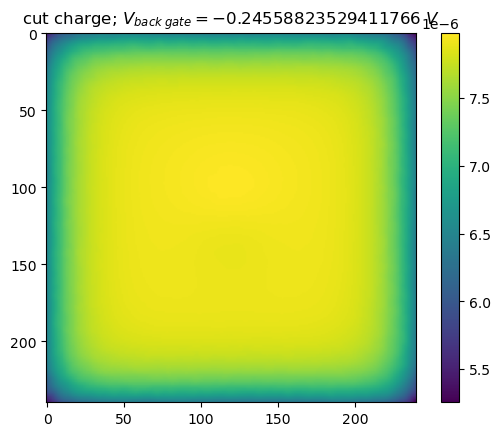

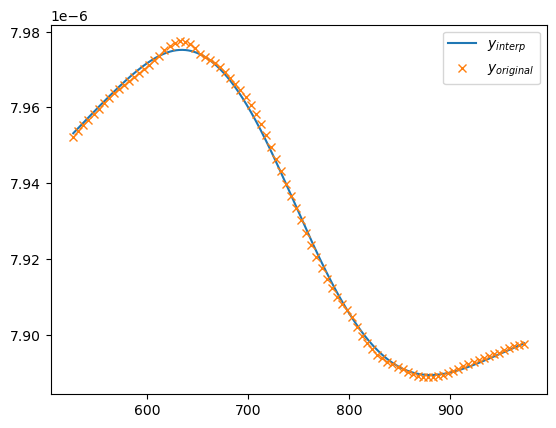

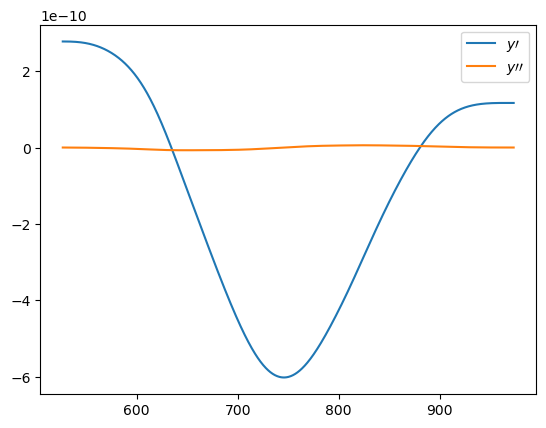

sep index: 490
alternative sep index: 490
sep index: 44
alternative sep index: 44
sep index: 119
alternative sep index: 119


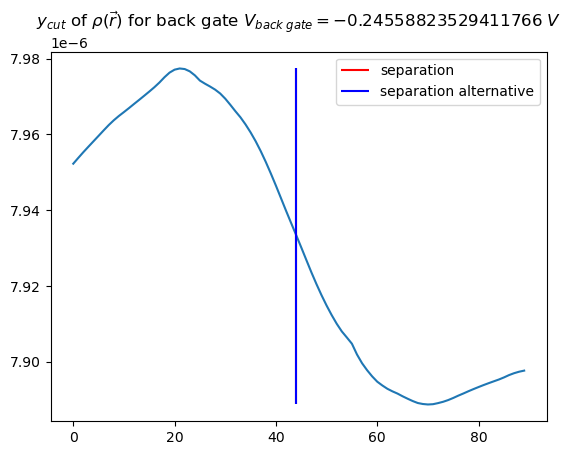

In [ ]:
### induced dipole moment
# charge array
induced_charge = test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n))
middle_index = math.floor(induced_charge.shape[0]/2)
y_cut = induced_charge[:,middle_index]


# cut boundaries; finite size effects; 10% is removed
#cut_percentage = 0.2
cut_index = int(cut_percentage/2 * induced_charge.shape[0])
induced_charge = induced_charge[cut_index:fem_n - cut_index, cut_index:fem_n - cut_index]
#y_cut = y_cut[cut_index:fem_n - cut_index]
plt.imshow(induced_charge)
plt.title(f'cut charge; $V_{{back\\;gate}}={back_gate}\\;V$')
plt.colorbar()
plt.show()

# find separation
#larger_cut_percentage = 0.6
larger_cut_index = int(larger_cut_percentage/2 * fem_n)
y_cut = y_cut[larger_cut_index:fem_n - larger_cut_index]

# x values
dx = vac_box_width/(fem_n - 1)
x_max = (fem_n - 1) * dx
x = np.linspace(0, x_max, fem_n)
#print(x[0])
#print(x[-1])

x = x[larger_cut_index:fem_n - larger_cut_index]


spline = interpolate.make_smoothing_spline(x, y_cut, lam=100000)
x_new = np.linspace(x[0], x[-1], 1000)

y_interp = spline(x_new)
y_prime = spline(x_new, nu=1)
y_double_prime = spline(x_new, nu=2)
plt.plot(x_new, y_interp, label='$y_{interp}$')
plt.plot(x, y_cut, 'x', label='$y_{original}$')
#plt.plot(x_new, y_prime, label='$y\\prime$')
#plt.plot(x_new, y_double_prime, label='$y\\prime \\prime$')
#plt.xlim((120, 130))
plt.legend()
plt.show()

plt.plot(x_new, y_prime, label='$y\\prime$')
plt.plot(x_new, y_double_prime, label='$y\\prime \\prime$')
plt.legend()
plt.show()


max_index = np.argmax(y_double_prime)
min_index = np.argmin(y_double_prime)

if max_index < min_index:
    sep_index = max_index + np.argmin(abs(y_double_prime[max_index:min_index]))
elif min_index < max_index:
    sep_index = min_index + np.argmin(abs(y_double_prime[min_index:max_index]))

sep_index_alt = np.argmax(abs(y_prime))
print(f'sep index: {sep_index}')
print(f'alternative sep index: {sep_index_alt}')

# bring sep_index back to original fem_n
sep_index = np.argmin(abs(x - x_new[sep_index]))
sep_index_alt = np.argmin(abs(x - x_new[sep_index_alt]))

print(f'sep index: {sep_index}')
print(f'alternative sep index: {sep_index_alt}')
sep_index_final = larger_cut_index - cut_index + sep_index
sep_index_alt_final = larger_cut_index - cut_index + sep_index_alt
print(f'sep index: {sep_index_final}')
print(f'alternative sep index: {sep_index_alt_final}')

# split charge array
top_charge = induced_charge[:sep_index_final, :]
bot_charge = induced_charge[sep_index_final:, :]


plt.plot(y_cut)
plt.vlines(sep_index, np.min(y_cut), np.max(y_cut), color='r', label='separation')
plt.vlines(sep_index_alt, np.min(y_cut), np.max(y_cut), color='b', label='separation alternative')
#plt.hlines(mean, 0, len(y_cut), color='g', label='mean')
plt.title(f'$y_{{cut}}$ of $\\rho(\\vec{{r}})$ for back gate $V_{{back\\;gate}}={back_gate} \\; V$')
plt.legend()

In [ ]:
### find centers of charges

dx = vac_box_width/(fem_n - 1)
x_max = (fem_n - 1) * dx
x = np.linspace(0, x_max, fem_n)
y = np.linspace(0, x_max, fem_n)

# cut x and y; ignore boundary effects
x = x[cut_index:fem_n - cut_index]
y = y[cut_index:fem_n - cut_index]

# meshgrid
x_top = x[:sep_index_final]
x_bot = x[sep_index_final:]
X_top, Y_top = np.meshgrid(x_top, y, indexing='ij')
X_bot, Y_bot = np.meshgrid(x_bot, y, indexing='ij')

# top
shape_top = top_charge.shape
p_top_x = np.trapezoid(np.trapezoid(abs(top_charge) * X_top, dx=dx, axis=0), dx=dx, axis=0)
p_top_y = np.trapezoid(np.trapezoid(abs(top_charge) * Y_top, dx=dx, axis=0), dx=dx, axis=0)

Q_top = np.trapezoid(np.trapezoid(abs(top_charge), dx=dx, axis=0), dx=dx, axis=0) * test_solver.blg_height

p_top = (np.array([p_top_x, p_top_y]) * test_solver.blg_height)
center_of_charge_top = p_top/Q_top

# bottom
p_bot_x = np.trapezoid(np.trapezoid(abs(bot_charge) * X_bot, dx=dx, axis=0), dx=dx, axis=0)
p_bot_y = np.trapezoid(np.trapezoid(abs(bot_charge) * Y_bot, dx=dx, axis=0), dx=dx, axis=0)

Q_bot = np.trapezoid(np.trapezoid(abs(bot_charge), dx=dx, axis=0), dx=dx, axis=0) * test_solver.blg_height

p_bot = (np.array([p_bot_x, p_bot_y]) * test_solver.blg_height)
center_of_charge_bot = p_bot/Q_bot

# dipole moment
print(Q_top)
print(Q_bot)
print(Q_bot + Q_top)
print(test_solver.total_charge)

p = p_bot + p_top
#print(p)
#print(np.linalg.norm(p)/(vac_box_width * vac_box_width))
print(center_of_charge_top)

0.7602636955042859
0.720282218438242
1.4805459139425279
1.8901493760569383
[457.53409751 750.03238838]


In [ ]:
# distance between centers of charges
d_vec = center_of_charge_top - center_of_charge_bot
print(d_vec)
print(test_solver.d_vec)
print(np.linalg.norm(d_vec))
print(test_solver.separation)

[-5.93047045e+02  2.19924909e-01]
[-5.92933996e+02  2.21371529e-01]
593.047085286353
592.9340369273011


In [ ]:
print(center_of_charge_top)
print(center_of_charge_bot)
print(test_solver.center_of_charge_top)
print(test_solver.center_of_charge_bot)
print(Q_top)
print(Q_bot)
print(test_solver.Q_top)
print(test_solver.Q_bot)
print(test_solver.sep_index)
print(sep_index_final)

[457.53409751 750.03238838]
[1050.58114201  749.81246347]
[455.07237138 750.0340463 ]
[1048.00636698  749.81267477]
0.7602636955042859
0.720282218438242
0.7539177958121177
0.726611944702625
120
121


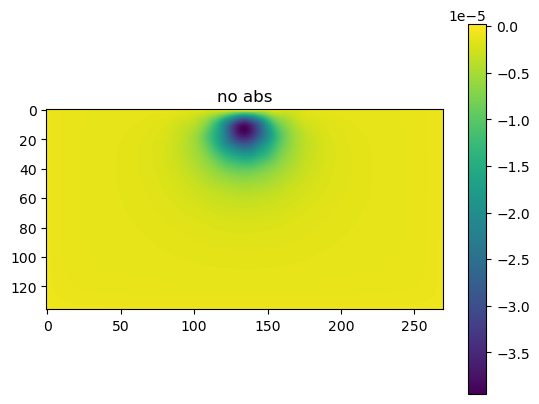

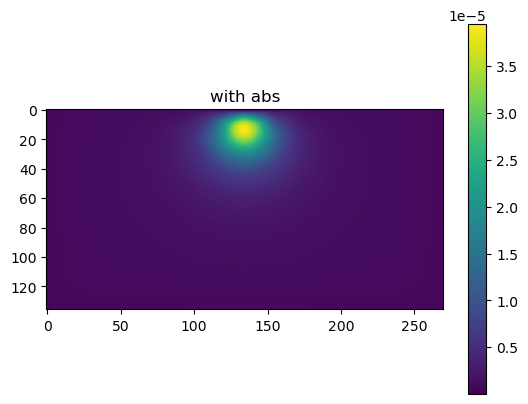

In [ ]:
plt.imshow(bot_charge)
plt.colorbar()
plt.title('no abs')
plt.show()

plt.imshow(abs(bot_charge))
plt.colorbar()
plt.title('with abs')
plt.show()

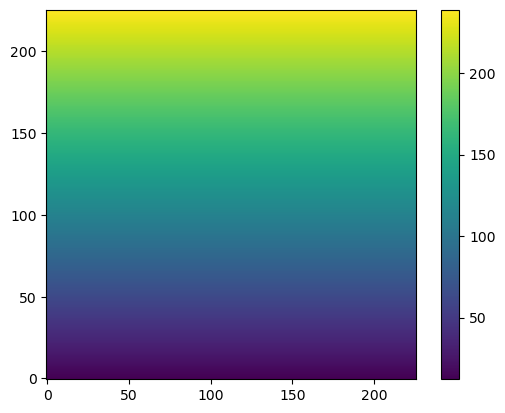

In [ ]:
X_con = np.concatenate([X_top, X_bot])
plt.imshow(X, origin='lower')
plt.colorbar()

[[ 12.09657909  12.09657909  12.09657909 ...  12.09657909  12.09657909
   12.09657909]
 [ 13.10462734  13.10462734  13.10462734 ...  13.10462734  13.10462734
   13.10462734]
 [ 14.1126756   14.1126756   14.1126756  ...  14.1126756   14.1126756
   14.1126756 ]
 ...
 [236.89134046 236.89134046 236.89134046 ... 236.89134046 236.89134046
  236.89134046]
 [237.89938872 237.89938872 237.89938872 ... 237.89938872 237.89938872
  237.89938872]
 [238.90743698 238.90743698 238.90743698 ... 238.90743698 238.90743698
  238.90743698]]


In [ ]:
print(test_solver.dipole_moment)
print(test_solver.total_charge)

8.3277708
2.4601692094066854


In [ ]:
# potential straight up in z-direction
diagonal_vec = np.array([vac_box_width, vac_box_width, height_bottom + blg_grapheneheight + height_top + vac_box_width])
diagonal = np.linalg.norm(diagonal_vec)
diagonal_unit_vec = diagonal_vec/diagonal

starting_point = np.array([0.45 * vac_box_width, 0.45 * vac_box_width, 0])

#rs = np.linspace(0, diagonal, 400)
rs = np.linspace(0, blg_grapheneheight + vac_box_width + height_bottom + height_top, 400)

gfu_values = []

for r in rs:
    #print(r)
    p = starting_point + r * np.array([0,0,1]) #diagonal_unit_vec
    gfu_values.append(test_solver.gfu(test_solver.mesh_dipole(*p)))

In [ ]:
plt.plot(rs, gfu_values)
plt.title("potential in z-direction next to dipole")
plt.xlabel('$z$')
plt.ylabel('$\\phi(z)$')

In [ ]:
# potential on main diagonal (in BLG)
gfu_values_diag =[]

diagonal_vec = np.array([vac_box_width, vac_box_width, blg_grapheneheight])
diagonal = np.linalg.norm(diagonal_vec)
diagonal_unit_vec = diagonal_vec/diagonal

starting_point = np.array([0.0, 0.0, height_bottom])

rs_diag = np.linspace(0, diagonal, 400)

gfu_values = []

for r in rs_diag:
    #print(r)
    p = starting_point + r * diagonal_unit_vec
    gfu_values_diag.append(test_solver.gfu(test_solver.mesh_dipole(*p)))

In [ ]:
plt.plot(rs_diag, gfu_values_diag)
plt.title("potential on main diagonal in BLG")
plt.xlabel('$r$')
plt.ylabel('$\\phi$')

In [ ]:
### dipole moment without splitting
X, Y = np.meshgrid(x, y, indexing='ij')

p_x = np.trapezoid(
    np.trapezoid(induced_charge * X, y, axis=1),
    x,
    axis=0
)

p_y = np.trapezoid(
    np.trapezoid(induced_charge * Y, y, axis=1),
    x,
    axis=0
)

p = np.array([p_x, p_y])
print(p)
print(np.linalg.norm(p) * test_solver.blg_height/(vac_box_width * vac_box_width))

[167.68611922 169.39016469]
0.01277566568946103


In [ ]:
x = np.linspace(0, x_max, fem_n)
y = np.linspace(0, x_max, fem_n)

Q_ind = np.trapezoid(
    np.trapezoid(test_solver.gfQ(test_solver.meshptsMid).reshape((fem_n, fem_n)), y, axis=1),
    x,
    axis=0
)
print(Q_ind)

0.7342900711645773


In [ ]:
V_increments = -1.0
number_increments = 5
max_hs = np.linspace(vac_box_width/5, vac_box_width/40, number_increments)
print(max_hs)

fem_ns = np.linspace(100, 1000, number_increments).round().astype(int)
print(fem_ns)

test_solver_increments = dipole_poisson_solver(dipole_moment_debye, dipole_d, dipole_position, inplane_hBn_bulk, outofplane_hBn_bulk, inplane_graphene, outofplane_graphene, epsilon_0)

[50.     39.0625 28.125  17.1875  6.25  ]
[ 100  325  550  775 1000]


In [ ]:

test_solver.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_h)
test_solver.solve_without_BLG(back_gate)
test_solver.solve(fem_n, epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, starting_alpha=0.01)

In [ ]:
times = np.zeros((number_increments, number_increments))
its = np.zeros((number_increments, number_increments))

# i over max_hs and j over fem_ns
for i in range(number_increments):
    for j in range(number_increments):
        test_solver_increments.build_geometry(vac_box_width, height_bottom, height_top, blg_grapheneheight, sphere_radius, max_hs[i])
        test_solver_increments.solve_without_BLG(V_increments)
        test_solver_increments.solve(fem_ns[j], epsilon_z, idos_interpolated, pot_min, pot_max, en_min, en_max, starting_alpha=0.01)

        times[i, j] = test_solver_increments.solver_time
        its[i, j] = test_solver_increments.global_it[0]

# 0   rho_n-1 - rho_n (max):  0.0004033599750714218
# 0   |q_n-1 - q_n| :  78.7106689921979
# 1   rho_n-1 - rho_n (max):  0.000692456293255215
# 1   |q_n-1 - q_n| :  115.5674774302002
# 2   rho_n-1 - rho_n (max):  0.0008065655064726969
# 2   |q_n-1 - q_n| :  160.766589814781
# 3   rho_n-1 - rho_n (max):  0.0002789710610026627
# 3   |q_n-1 - q_n| :  51.0908069860417
# 4   rho_n-1 - rho_n (max):  0.0005452402355581436
# 4   |q_n-1 - q_n| :  88.1720458887123
# 5   rho_n-1 - rho_n (max):  0.0005299718755701044
# 5   |q_n-1 - q_n| :  101.43592278787474
# 6   rho_n-1 - rho_n (max):  0.00021674771125571631
# 6   |q_n-1 - q_n| :  35.35130337414307
# 7   rho_n-1 - rho_n (max):  0.00042627656574872603
# 7   |q_n-1 - q_n| :  65.73981942088051
# 8   rho_n-1 - rho_n (max):  0.00017116357756875175
# 8   |q_n-1 - q_n| :  18.65936535162775
# 9   rho_n-1 - rho_n (max):  0.00011699177441437913
# 9   |q_n-1 - q_n| :  2.7609577093085704
# 10   rho_n-1 - rho_n (max):  4.0931210727008236e-05
# 10   |q_n-1 -

In [ ]:
print(its)
print(times)

[[33. 34. 34. 34. 34.]
 [30. 34. 33. 33. 33.]
 [33. 33. 33. 33. 33.]
 [31. 31. 31. 31. 31.]
 [30. 30. 30. 30. 30.]]
[[ 2.06406927  3.36961174  5.03303123  6.64997196  9.04510021]
 [ 2.0876472   4.66625428  4.77976537  8.61392879 13.82960987]
 [ 2.30927825  3.50225687  4.9332099   6.86748672 10.77442789]
 [ 4.3435061   3.91893268  5.18815708  7.26661539  9.5957222 ]
 [25.2487042  25.23701596 28.44606376 29.55219913 35.8329649 ]]


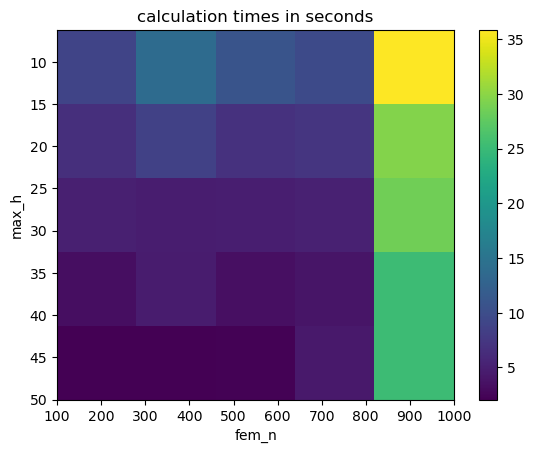

In [ ]:
x = max_hs
y = fem_ns

X, Y = np.meshgrid(x,y, indexing='ij')
z = times

plt.imshow(
    z.T,
    origin='lower',
    extent=[y.min(), y.max(), x.max(), x.min()],
    aspect='auto'
)
plt.title('calculation times in seconds')
plt.xlabel('fem_n')
plt.ylabel('max_h')
plt.colorbar()
plt.show()

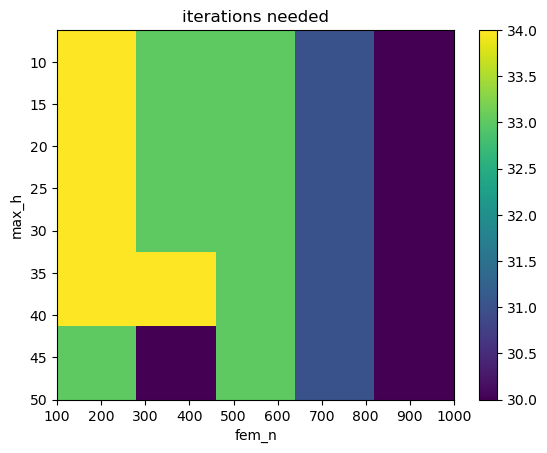

In [ ]:
z = its

plt.imshow(
    z.T,
    origin='lower',
    extent=[y.min(), y.max(), x.max(), x.min()],
    aspect='auto'
)
plt.title('iterations needed')
plt.xlabel('fem_n')
plt.ylabel('max_h')
plt.colorbar()
plt.show()